Nombre: juan paredes       
"Tipos de representacion de datos"=https://colab.research.google.com/drive/1tovClWbwysreNjhJx4RzGXULujPLd5vH

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from collections import Counter

In [ ]:
hotel_bookings = sns.load_dataset('flights')
hotel_bookings.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [ ]:
matriz = hotel_bookings.values
print(f"Matriz de hotel_bookings:\n{matriz}")
#

Matriz de hotel_bookings:
[['Resort Hotel' 0 342 ... 0 'Check-Out' '2015-07-01']
 ['Resort Hotel' 0 737 ... 0 'Check-Out' '2015-07-01']
 ['Resort Hotel' 0 7 ... 0 'Check-Out' '2015-07-02']
 ...
 ['City Hotel' 0 34 ... 4 'Check-Out' '2017-09-07']
 ['City Hotel' 0 109 ... 0 'Check-Out' '2017-09-07']
 ['City Hotel' 0 205 ... 2 'Check-Out' '2017-09-07']]


In [ ]:
print(matriz.shape)

(119390, 32)


array([['Resort Hotel', 0, 342, 2015, 'July', 27],
       ['Resort Hotel', 0, 737, 2015, 'July', 27],
       ['Resort Hotel', 0, 7, 2015, 'July', 27],
       ['Resort Hotel', 0, 13, 2015, 'July', 27]], dtype=object)

2776.0


arrival_date_year
2015    21996.0
2016    56707.0
2017    40687.0
dtype: float64


arrival_date_month
May        5895.5
October    5580.0
April      5544.5
dtype: float64


Mayo y  octubre, en promedio com mas llegadas en el mes por año 2016 y 2017 promedio.

In [ ]:
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

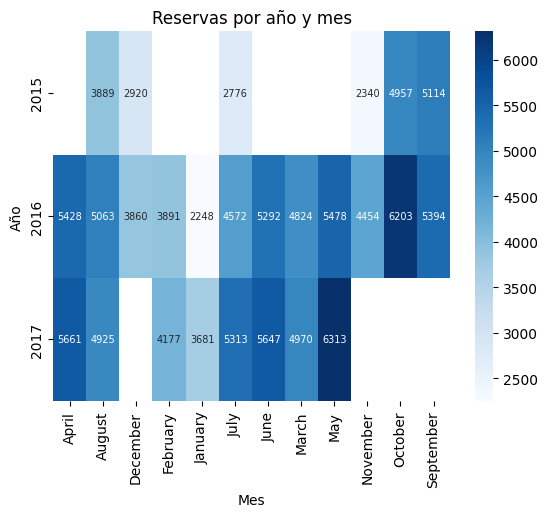

            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000


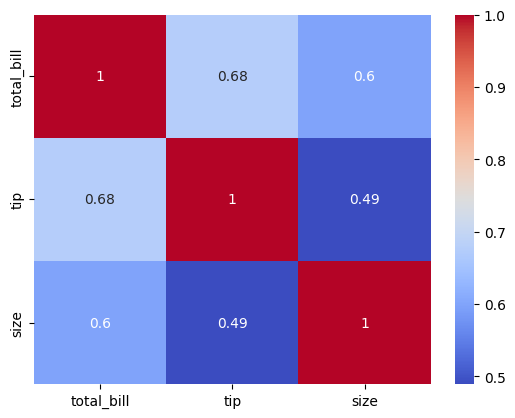

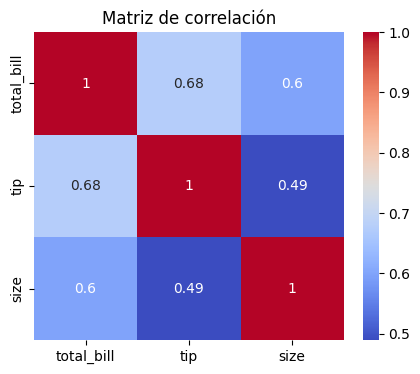

In [ ]:
propinas = sns.load_dataset('tips')
corr = propinas[['total_bill', 'tip', 'size']].corr()
sns.heatmap(corr, cmap='coolwarm', annot=True)
print(corr)

plt.figure(figsize=(5, 4))
sns.heatmap(corr,annot=True, cmap='coolwarm')
plt.title('Matriz de correlación')
plt.show()
#



*   El mes con tarifa mas alta suele ser julio o agosto en el hotel Resort.
*   La correlacio mas fuerte suele ser entre lead_time y total_of_special_requests (o variables de estadia). ¿Tiene sentido? Si: mientras antes se reserva, mas solicitudes especiales se hacen.



In [ ]:
import unicodedata


In [ ]:
def limpiar(texto):
    texto = texto.lower()
    texto = unicodedata.normalize('NFKD', texto)
    texto = texto.encode('ascii', 'ignore').decode('utf-8')
    for signo in '!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~':
        texto = texto.replace(signo, '')
    return texto

,resena,limpia
0,¡Excelente servicio y comida deliciosa!,excelente servicio y comida deliciosa
1,El lugar estaba bastante sucio... #decepcionante,el lugar estaba bastante sucio decepcionante


In [ ]:
print(df_txt['resena'][0])
print(df_txt['limpia'][0])
#

¡Excelente servicio y comida deliciosa!
excelente servicio y comida deliciosa


In [ ]:
stopwords = ['el', 'la', 'los', 'las', 'un', 'una', 'y', 'en', 'de', 'del',
             'a', 'me', 'lo', 'no', 'es', 'muy', 'per', 'todo', 'siempre',
             'estaba', 'estan', 'venia', 'vuelvo', 'nadie']


In [ ]:
todas = []
for texto in df_txt['limpia']:
  for palabra in texto.split():
    if palabra not in stopwords:
      todas.append(palabra)


In [ ]:
frecuencias = Counter(todas)
print(len(todas), len(frecuencias))
frecuencias.most_common(10)

8 8


[('excelente', 1),
 ('servicio', 1),
 ('comida', 1),
 ('deliciosa', 1),
 ('lugar', 1),
 ('bastante', 1),
 ('sucio', 1),
 ('decepcionante', 1)]

In [ ]:
from re import X
from sklearn.feature_extraction.text import CountVectorizer

vectorizador = CountVectorizer(stop_words=stopwords)
X = vectorizador.fit_transform(df_txt['limpia'])
dtm = pd.DataFrame(X.toarray(), columns=vectorizador.get_feature_names_out())



In [ ]:
print(dtm.shape)

(2, 8)


,excelente,servicio,comida,deliciosa
0,1,1,1,1
1,0,0,0,0


In [ ]:
# cuantas categorias hay



Cantidad de categorías en reserved_room_type: 10
Categorías: ['C' 'A' 'D' 'E' 'G' 'F' 'H' 'L' 'P' 'B']


,count
reserved_room_type,
A,85994
D,19201
E,6535
F,2897
G,2094
B,1118
C,932
H,601
P,12


In [ ]:
# nivel 1: la primera categoria
print(categorias_habitacion[0])

C


In [ ]:
# nivel 2: la segunda subcategoria de esa categoria
print(hotel_bookings[hotel_bookings['reserved_room_type'] == categorias_habitacion[0]]['assigned_room_type'].unique())
#

['C' 'I' 'F' 'H' 'G' 'A' 'E' 'D' 'B']


In [ ]:
# nivel 3 (hoja): el primer producto de esa subcategoria
print('catalogo', hotel_bookings[hotel_bookings['reserved_room_type'] == categorias_habitacion[0]]['assigned_room_type'].unique()[0])


catalogo C


               hotel  is_canceled  lead_time  arrival_date_year  \
0       Resort Hotel            0        342               2015   
1       Resort Hotel            0        737               2015   
2       Resort Hotel            0          7               2015   
3       Resort Hotel            0         13               2015   
4       Resort Hotel            0         14               2015   
...              ...          ...        ...                ...   
119385    City Hotel            0         23               2017   
119386    City Hotel            0        102               2017   
119387    City Hotel            0         34               2017   
119388    City Hotel            0        109               2017   
119389    City Hotel            0        205               2017   

       arrival_date_month  arrival_date_week_number  \
0                    July                        27   
1                    July                        27   
2                    July     

In [ ]:
for cat in catalogo['hotel_bookings']['reserved_room_type'].unique():
  print(cat)


C
A
D
E
G
F
H
L
P
B


{
  "nombre": "Categoría 3",
  "subcategorias": []
}


In [ ]:
plano = pd.json_normalize(catalogo['categorias'])
print(plano)
catalogo['categorias'],
record_path=['subcategorias']
meta=['nombre']

plano = pd.json_normalize(catalogo['categorias'], record_path=['subcategorias'], meta=['nombre'])
print(plano)
#





        nombre subcategorias
0  Categoría 1            []
1  Categoría 2            []
2  Categoría 3            []
Empty DataFrame
Columns: [nombre]
Index: []


In [ ]:
import plotly.express as px



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
fig2 = px.sunburst(plano, path=['categoria', 'subcategoria'], values='precio', title='Catalogo: categoria > subcategoria')
fig2.show()
#

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
print(mi_df.shape)
print(mi_df.dtypes)


(119390, 32)
hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                

In [ ]:
col_cat1 = 'COLUMNA_CATEGORIA'
col_cat2 = 'COLUMNA_SUBCATEGORIA'
col_num = 'COLUMNA_NUMERICA'
colum_texto = 'COLUMNA_DE_TEXTO'
#

Index(['A', 'D', 'E', 'F', 'G', 'B', 'C', 'H', 'P', 'L'], dtype='object', name='reserved_room_type')
Index(['D', 'E', 'F', 'G', 'B', 'C', 'H', 'P', 'L'], dtype='object', name='reserved_room_type')


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303.0,NaN,0,Transient,103.0,0,1,Check-Out,2015-07-03


assigned_room_type,B,C,D,E,F,G,H,L,P
reserved_room_type,,,,,,,,,
A,95.000,73.800,70.00,75.00,80.00,80.000,66.50,NaN,NaN
B,86.630,NaN,98.20,70.75,136.25,145.000,NaN,NaN,NaN
C,204.125,164.570,51.92,113.57,79.00,139.285,66.00,NaN,NaN
D,113.760,121.625,121.67,105.00,108.00,124.750,106.00,NaN,NaN
E,107.920,90.000,97.47,115.00,113.24,111.000,142.00,NaN,NaN
F,78.420,NaN,56.25,140.14,177.30,177.300,131.88,NaN,NaN
G,117.725,134.000,NaN,0.00,171.60,176.670,153.00,NaN,NaN
H,NaN,NaN,123.00,NaN,NaN,146.000,184.90,NaN,NaN
L,172.000,136.000,NaN,NaN,200.00,NaN,150.00,8.0,NaN


In [ ]:
print(mi_matriz.shape)
#

(10, 9)


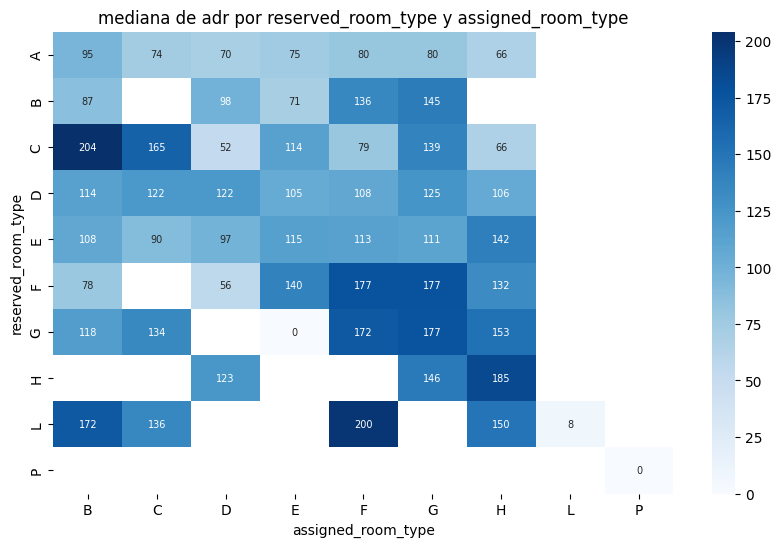

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(mi_matriz, cmap='Blues', annot=True, fmt='.0f', annot_kws={'size': 7})
plt.title(f'mediana de {col_num} por {col_cat1} y {col_cat2}')
plt.xlabel(col_cat2)
plt.ylabel(col_cat1)
plt.show()
#

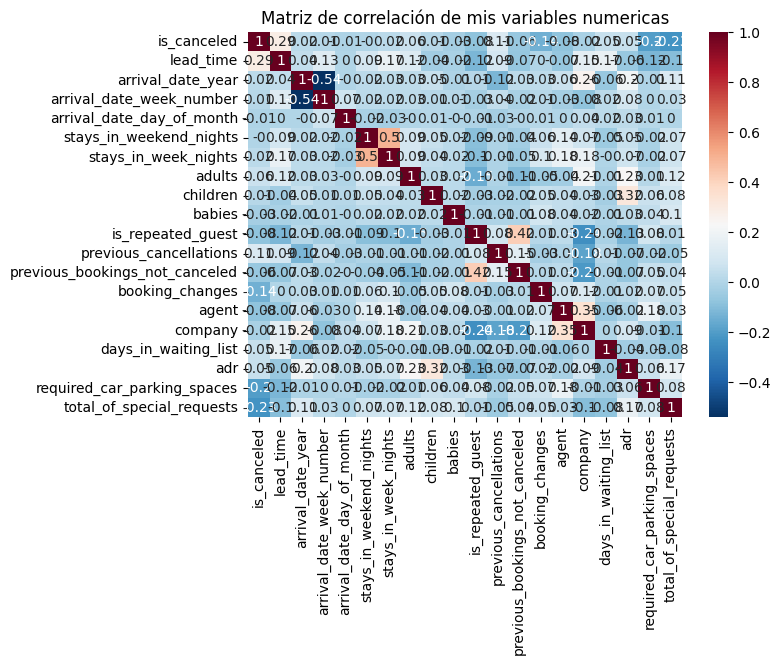

In [ ]:
numericas = mi_df.select_dtypes(include='number')
mi_corr = numericas.corr().round(2)

plt.figure(figsize=(7, 5))
sns.heatmap(mi_corr, cmap='RdBu_r', annot=True)
plt.title('Matriz de correlación de mis variables numericas')
plt.show()
#

Las 3 mas frecuentes son: a, d, e. Son los codigos de los tipos de habitacion reservados. Esto nos dice que las habitaciones  tipo A son las mas solicitadaa, seguidas por la D y la E lo que indica que las opciones estandar son las preferidas por los huespedes,


En este caso no, porque son codigos unicos de una sola letra. Sin embargo, usaremos otra columna  con texto libre, si apareccerian variaciones como singular/plural o distintas grafias.  Esto afecta el conteo porque el computador las cuenta como palabras distintas,, cuando en realida significan lo mismo, por lo que el resultado final subestima su frcecuencia real. Se soluciona con lematizacion.

Conclucion completa -hotelbookekings



*   Mi matriz de tipo de hotel x mes de llegad mostro que la convinacion  con el valor  mas alto es Resort Hotel  y agosto($236)
*   Las variables mas correlacionadas  son tota_nightns y adr (corelacion de 0.54), lo quesignifica que a mayor cantidadde noches reservadas, la tarifa diaria tiende a ser mas alta


*   En la colunma de texto reserved_room_type las palabras  mas frecuente fueron A, D Y E lo que endica en la habitacion tpo A es la mas solicitada, seguida por la D y la E



*   Las columnas hotel y arrival_date_moonth no forma una jerarquia perfecta.La rama con mas registros city hotel.
*   La representacion mas util para mis datos fue la matriz con mapa de calor porque permite ver de un solo vistaso como varian los precios segun el tipo de hotel y la temporada del año.


*  



